# 08 · 参数化三维热方程：同时输入初值、扩散率与时间

**前置：** 03、07。**目标：** 把 PDE 参数作为输入，学习 $\mathcal G:(u_0,\nu,T)\mapsto u(T)$，避免把固定参数网络误用于新参数。

$u_t=\nu\Delta u$，空间为周期 $[0,1)^3$。训练范围 $\nu\in[0.01,0.08]$、$T\in[0.05,0.30]$；测试包括范围内新组合和范围外实验。

解析参考：每个三维 Fourier 模式乘 $e^{-4\pi^2\nu|\boldsymbol k|^2T}$。这是整族三维 PDE 的固定查询时间映射，不是逐时间步求解器。

## 原理详解 A：参数化解算子与输入完整性

本章学习
$$
\mathcal G:(u_0,\nu,T)\mapsto u(\cdot,T),
$$
不是只学习 $u_0\mapsto u(T_*)$。同一个 u0 在不同 $\nu,T$ 下有不同解，所以省略参数会把不同目标对应到同一个网络输入。仅靠加深网络无法修复这个输入定义上的不确定性。

解析模式为
$$
\widehat u_{\boldsymbol k}(T)
=e^{-4\pi^2|\boldsymbol k|^2\nu T}\widehat u_{0,\boldsymbol k}.
$$
当 $\nu,T$ 固定时，它对 u0 线性；当把参数也作为输入时，映射整体具有非线性的参数依赖。两种说法不矛盾。

本方程只依赖乘积 $\eta=\nu T$。因此两组参数若满足 $\nu_1T_1=\nu_2T_2$，在同一 u0 下真实解相同。这可以做成物理等价性检查；网络若给出明显不同解，说明它没有完全识别这个结构。

两个常参数不是两条新的空间函数，但在卷积网络中把它们广播成常数体积，可让每个位置的通道混合读到条件。它们经 lifting 与激活影响频谱特征处理。常数通道自身只有零频率，不妨碍非线性网络把条件与其他空间通道相互作用。

## 原理详解 B：归一化、无量纲时间与衰减性质

输入参数按预设训练区间归一化：
$$
\widetilde\nu=\frac{\nu-0.01}{0.07},\qquad
\widetilde T=\frac{T-0.05}{0.25}.
$$
这样参数通道数量级接近初值通道，有利于优化。区间是实验定义，不是从测试集估计，因此不会造成测试统计量泄漏。

对域长度 L，热方程的重要无量纲组合是 $\nu T/L^2$。本章 $L=1$，因此 $\nu T$ 直接控制衰减。换域尺度却保留同一参数输入与数据定义，会改变物理含义。

周期热方程保留均值，因为零频率乘数为 1；由每个模式衰减还可得能量不增。解算子族满足
$$
S_{T_1+T_2}^{\nu}=S_{T_2}^{\nu}\circ S_{T_1}^{\nu}.
$$
代码对参考求解器检查这个半群性质，但本章没有把它写入模型损失，因此预测未必精确满足。

$T=0$ 时真实算子是恒等映射。当前训练区间从 0.05 开始，所以查询 0 属于时间范围外测试，不能默认它会准确恢复初值。若要求初始时刻准确，应加入 T=0 监督，或设计结构上满足初值的参数化。

## 原理详解 C：多参数泛化与范围外误差

参数范围内的新组合、范围外参数和更密空间网格，是三种不同变化：

- 范围内新组合主要检查对参数变化与新初值函数的联合泛化。
- 范围外参数改变衰减规律的训练覆盖范围，测试的是外推。
- 更密空间网格保持 u0、参数与物理区域不变，检查离散表示迁移。

范围外归一化值不截到 [0,1]，因为截断会让所有更大参数映射成同一个输入，丢失它们之间的区别。但保留真实输入值也不保证网络能可靠外推。

衰减越强，目标解的非零模式越小。即使绝对误差没有显著增加，相对误差也可能因分母减小而放大。因此看范围外结果时，应同时看参考幅度、绝对误差和相对误差，不只比较一个百分比。

本章数据 MSE 也可能更偏重早时间、低扩散率等幅度较大的解。若要均衡各参数区域，可设计分层采样、按样本幅度归一化的损失或明确的相对损失，但需要重新报告训练协议。

**可验证推论：** 固定一个初值，在相同 $\nu T$ 下比较模型输出；固定扩散率，增加时间后比较零模和能量；固定函数与参数，比较不同网格的体积误差。每个实验都对应一个明确的物理命题。

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / "tutorial_utils.py").exists():
    ROOT = ROOT / "neural_operator_tutorials"
if not (ROOT / "tutorial_utils.py").exists():
    raise FileNotFoundError("Start Jupyter in PINO or neural_operator_tutorials")
sys.path.insert(0, str(ROOT))
import torch
get_ipython().run_line_magic("matplotlib", "inline")
from tutorial_utils import *
from tutorial_3d_utils import *
seed_all()
print("device:", DEVICE, "| smoke:", SMOKE)


device: cpu | smoke: False


## 1. 条件通道的含义

输入 shape 为 $[B,3,N,N,N]$，通道依次是 $u_0$、归一化 $\nu$、归一化 $T$。参数通道在每个空间位置取相同值。归一化界限直接取预先定义的训练区间，不使用测试统计量。

范围外参数会得到超出 [0,1] 的归一化值；我们不截断它，否则模型无法区分超出范围的真实参数。

In [2]:
N = 8 if SMOKE else 12
ntrain,ntest = (16,4) if SMOKE else (96,16)
def sample_parameters(count):
    return 0.01+0.07*torch.rand(count),0.05+0.25*torch.rand(count)
def pack_heat(initial,nu,time):
    B,nx,ny,nz = initial.shape
    pnu = ((nu-0.01)/0.07).reshape(B,1,1,1,1).expand(B,1,nx,ny,nz)
    ptime = ((time-0.05)/0.25).reshape(B,1,1,1,1).expand(B,1,nx,ny,nz)
    return torch.cat([initial[:,None],pnu,ptime],dim=1)
def heat_dataset(coeff,n,nu,time):
    initial = field3d(coeff,n)
    return pack_heat(initial,nu,time),heat3d(initial,nu,time)

atrain = torch.randn(ntrain,NCOEFF)
aval,atest = torch.randn(ntest,NCOEFF),torch.randn(ntest,NCOEFF)
nu_train,time_train = sample_parameters(ntrain)
nu_val,time_val = sample_parameters(ntest)
nu_test,time_test = sample_parameters(ntest)
train_in,train_out = heat_dataset(atrain,N,nu_train,time_train)
val_in,val_out = heat_dataset(aval,N,nu_val,time_val)
test_in,test_out = heat_dataset(atest,N,nu_test,time_test)
print("input channels u0, nu, T:",train_in.shape)

input channels u0, nu, T: torch.Size([96, 3, 12, 12, 12])


## 2. 先验证热方程性质

热半群满足 $\mathcal G_{t+s}(u_0)=\mathcal G_s(\mathcal G_t(u_0))$。周期解保留均值，平方积分随时间不增。参考求解器必须先满足这些性质；神经网络是否满足则需独立评估。

In [3]:
initial = test_in[:,0]
tpart = time_test/2
half = heat3d(initial,nu_test,tpart)
composition = heat3d(half,nu_test,tpart)
assert torch.allclose(composition,test_out,atol=2e-6,rtol=1e-5)
assert (test_out.mean((1,2,3))-initial.mean((1,2,3))).abs().max()<1e-6
assert (test_out.square().mean((1,2,3))<=initial.square().mean((1,2,3))+1e-6).all()
constant = torch.ones(2,N,N,N)
assert torch.allclose(heat3d(constant,torch.tensor([0.01,0.08]),0.2),constant,atol=1e-6)
print("reference semigroup / mean / energy checks passed")

reference semigroup / mean / energy checks passed


## 3. 网络结构不变，输入通道扩展

仍然使用 07 的四角块 3D FNO，`cin=3` 让 lifting 接收初值和两个条件。参数只有作为输入并在数据中变化，才可能支持对应条件的泛化。

In [4]:
class SpectralConv3d(nn.Module):
    """Four corners: +/- kx, +/- ky, nonnegative kz."""
    def __init__(self,width,modes=3):
        super().__init__()
        self.modes = modes
        self.weights = nn.ParameterList([
            nn.Parameter(torch.randn(width,width,modes,modes,modes,
                                     dtype=torch.cfloat)/width) for _ in range(4)])
    def forward(self,v):
        nx,ny,nz = v.shape[-3:]
        vf = torch.fft.rfftn(v,dim=(-3,-2,-1))
        m = min(self.modes,nx//2,ny//2,nz//2+1)
        if m<1: raise ValueError("Spatial dimensions must be >=2")
        out = torch.zeros_like(vf)
        blocks = [(slice(0,m),slice(0,m)),(slice(-m,None),slice(0,m)),
                  (slice(0,m),slice(-m,None)),(slice(-m,None),slice(-m,None))]
        for (sx,sy),weight in zip(blocks,self.weights):
            out[:,:,sx,sy,:m] = torch.einsum(
                "bixyz,ioxyz->boxyz",vf[:,:,sx,sy,:m],weight[:,:,:m,:m,:m])
        return torch.fft.irfftn(out,s=(nx,ny,nz),dim=(-3,-2,-1))

class FNO3d(nn.Module):
    """Input [B,C,Nx,Ny,Nz], output scalar field [B,Nx,Ny,Nz]."""
    def __init__(self,cin=1,width=8,modes=3,depth=2):
        super().__init__()
        self.lift = nn.Conv3d(cin+6,width,1)
        self.spectral = nn.ModuleList([SpectralConv3d(width,modes) for _ in range(depth)])
        self.local = nn.ModuleList([nn.Conv3d(width,width,1) for _ in range(depth)])
        self.project = nn.Sequential(nn.Conv3d(width,16,1),nn.GELU(),nn.Conv3d(16,1,1))
    def forward(self,a):
        shape = a.shape[-3:]
        grid = periodic_grid3d(shape,device=a.device,dtype=a.dtype)
        pos = torch.cat([(2*torch.pi*grid).sin(),(2*torch.pi*grid).cos()],dim=0)
        v = self.lift(torch.cat([a,pos[None].expand(len(a),-1,-1,-1,-1)],dim=1))
        for spectral,local in zip(self.spectral,self.local):
            v = torch.nn.functional.gelu(spectral(v)+local(v))
        return self.project(v).squeeze(1)


epoch    1 | train MSE 1.758e+00 | val relative L2 0.897


epoch   20 | train MSE 1.218e-02 | val relative L2 0.083


epoch   40 | train MSE 4.666e-03 | val relative L2 0.063


epoch   60 | train MSE 3.125e-03 | val relative L2 0.063


epoch   80 | train MSE 2.863e-03 | val relative L2 0.051


epoch  100 | train MSE 2.886e-03 | val relative L2 0.050


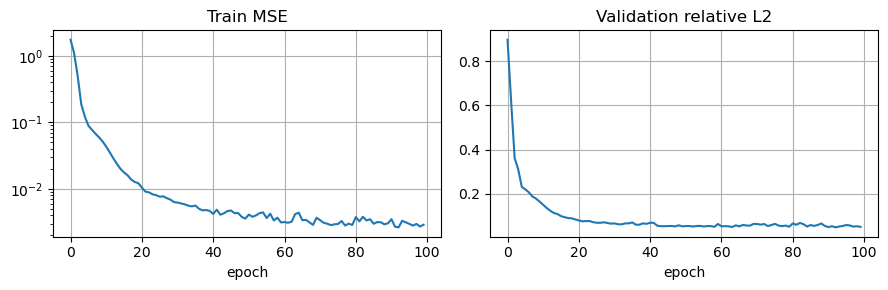

Test relative L2: mean=0.0411, median=0.0373, max=0.0808


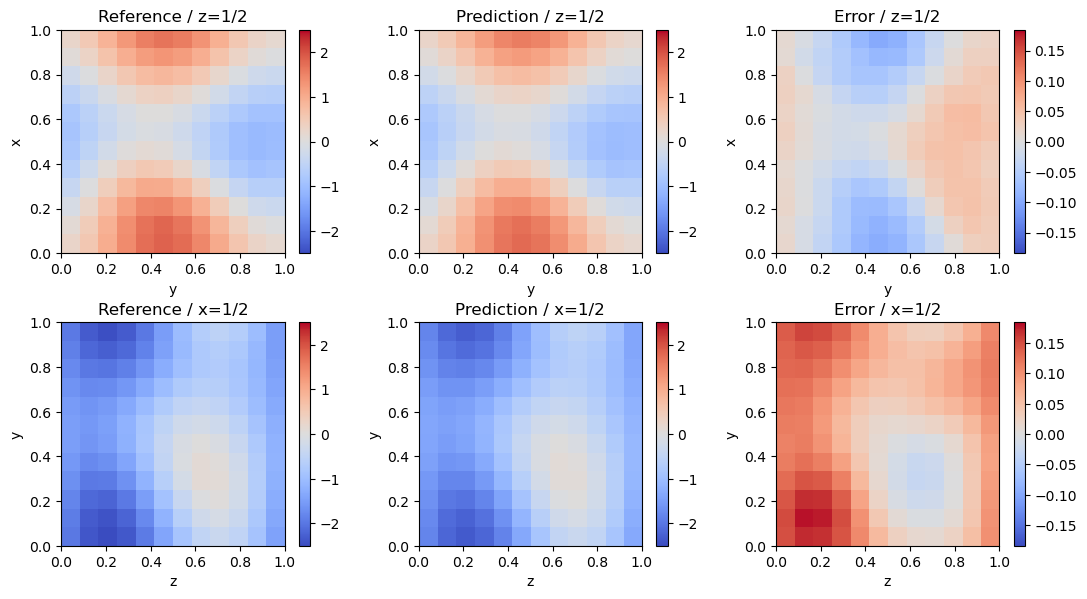

In [5]:
model = FNO3d(cin=3,width=8,modes=3)
history = fit(model,train_in,train_out,val_in,val_out,
              steps=epochs(100),batch=8,lr=0.003)
plot_history(history)
pred,error = report(model,test_in,test_out)
show_volume_slices(test_out,pred)

## 4. 控制变量看参数响应

保持同一个测试初值，比较低扩散率、低时间与高扩散率、高时间。此处选取的都是训练区间内条件，观察模型是否学到幅度衰减。曲线为穿过体积中心的 x 方向剖面。

Test relative L2: mean=0.0582, median=0.0534, max=0.0630


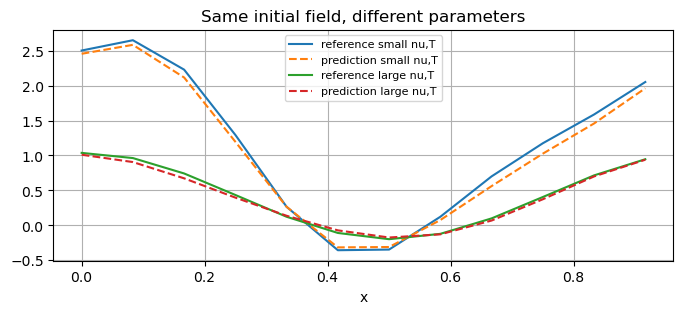

In [6]:
same_a = atest[:1].repeat(2,1)
nu_pair = torch.tensor([0.01,0.08])
time_pair = torch.tensor([0.05,0.30])
pair_in,pair_truth = heat_dataset(same_a,N,nu_pair,time_pair)
pair_pred,_ = report(model,pair_in,pair_truth)
axis = torch.arange(N)/N
for i,label in enumerate(["small nu,T","large nu,T"]):
    plt.plot(axis,pair_truth[i,:,N//2,N//2],label="reference "+label)
    plt.plot(axis,pair_pred[i,:,N//2,N//2],"--",label="prediction "+label)
plt.xlabel("x"); plt.title("Same initial field, different parameters")
plt.legend(fontsize=8); plt.show()

## 5. 同时检查更密网格与范围外参数

更密网格实验保持原测试初值函数和参数不变。范围外实验使用 $\nu=0.12,T=0.4$，超出训练区间；只是测量外推行为，不将其作为训练或选择超参数的依据。

Test relative L2: mean=0.0411, median=0.0373, max=0.0808


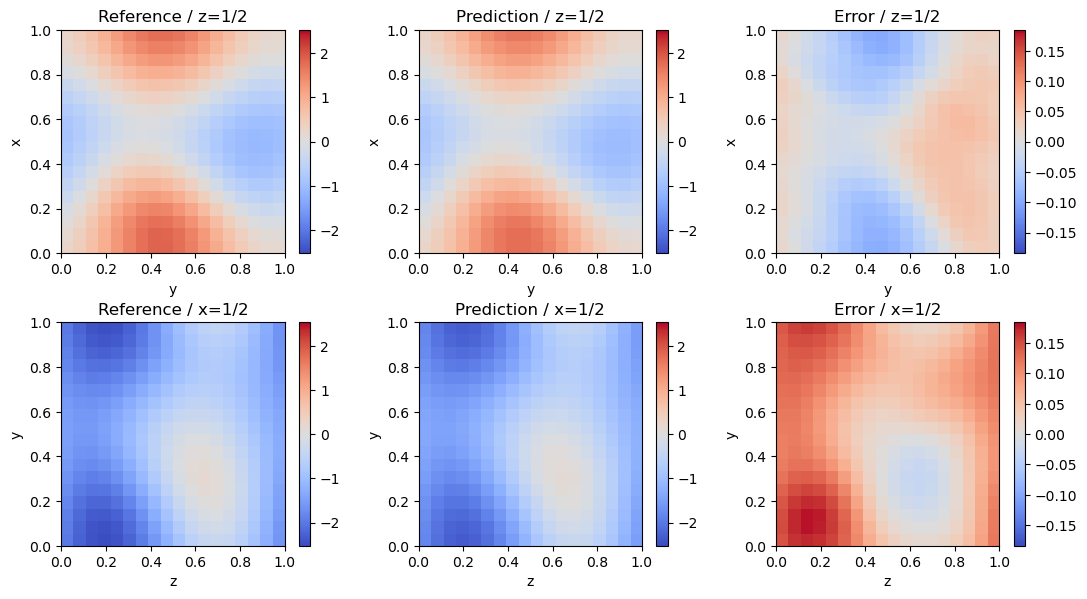

Test relative L2: mean=0.5773, median=0.5516, max=1.1615
within range: 0.04108291119337082 fine grid: 0.04108363762497902 outside range: 0.5772656202316284
Prediction mean drift: 0.0071438816376030445


In [7]:
fine_in,fine_out = heat_dataset(atest,12 if SMOKE else 18,nu_test,time_test)
finepred,fineerror = report(model,fine_in,fine_out)
show_volume_slices(fine_out,finepred)
ood_in,ood_out = heat_dataset(atest,N,torch.full((ntest,),0.12),torch.full((ntest,),0.4))
ood_pred,ood_error = report(model,ood_in,ood_out)
print("within range:",error.mean().item(),"fine grid:",fineerror.mean().item(),
      "outside range:",ood_error.mean().item())
print("Prediction mean drift:",
      (pred.mean((1,2,3))-test_in[:,0].mean((1,2,3))).abs().mean().item())

**练习：** ① 网络只输入初值、不输入条件，再比较测试误差；② 将 $T=0$ 样本加入训练，让初始条件成为监督的一部分；③ 对预测增加均值或能量约束；④ 构造相同 $\nu T$、不同 $\nu,T$ 的配对样本检查物理等价性。

**思考：** 本方程的解仅依赖乘积 $\nu T$。输入两个参数是为了学习条件编码；若有先验，可以改为只输入 $\nu T$ 并比较样本效率。